# Paper figure: UMAP by hierarchy complexity

The same UMAP coordinates are colored by four continuous properties of the raw RICO view hierarchy. Continuous scales avoid categorical color clutter and reveal whether the embedding space is organized by structural complexity. The accompanying nearest-neighbor comparison is computed in the original cosine space.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.neighbors import NearestNeighbors

from paper_embedding_analysis import DEFAULT_EMBEDDINGS_DIR, available_embedding_ids, deterministic_sample, fit_umap, load_embeddings, load_hierarchy_metrics, output_dir

sns.set_theme(context="paper", style="white", font_scale=1.05)
plt.rcParams.update({"figure.dpi": 130, "savefig.dpi": 300})

C:\Users\Jonathan\Dev\screen2vec-revisited\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
RANDOM_STATE = 42
MAX_SCREENS = 10_000
K_NEIGHBORS = 10
OUTPUT_DIR = output_dir("paper_umap_hierarchy_complexity")

In [3]:
available = available_embedding_ids(DEFAULT_EMBEDDINGS_DIR)
sample_ids = deterministic_sample(available, MAX_SCREENS, RANDOM_STATE)
metrics = load_hierarchy_metrics(sample_ids)
ids, X = load_embeddings(metrics["screen_id"], DEFAULT_EMBEDDINGS_DIR, description="Loading complexity sample")
row_order = pd.DataFrame({"screen_id": ids, "row": np.arange(len(ids))})
screens = metrics.merge(row_order, on="screen_id", validate="one_to_one").sort_values("row").reset_index(drop=True)
coords, pca = fit_umap(X, random_state=RANDOM_STATE)
screens[["umap_1", "umap_2"]] = coords
display(screens[["node_count", "max_depth", "clickable_count", "text_node_fraction"]].describe())

Loading complexity sample: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 10000/10000 [00:07<00:00, 1265.63it/s]


,node_count,max_depth,clickable_count,text_node_fraction
count,10000.00000,10000.000000,10000.000000,10000.000000
mean,96.94400,12.269900,17.475100,0.200685
std,95.05188,4.378924,19.393339,0.115393
min,2.00000,2.000000,0.000000,0.000000
25%,30.00000,9.000000,4.000000,0.126984
50%,66.00000,12.000000,11.000000,0.200000
75%,134.00000,15.000000,24.000000,0.264286
max,1608.00000,30.000000,267.000000,0.833333


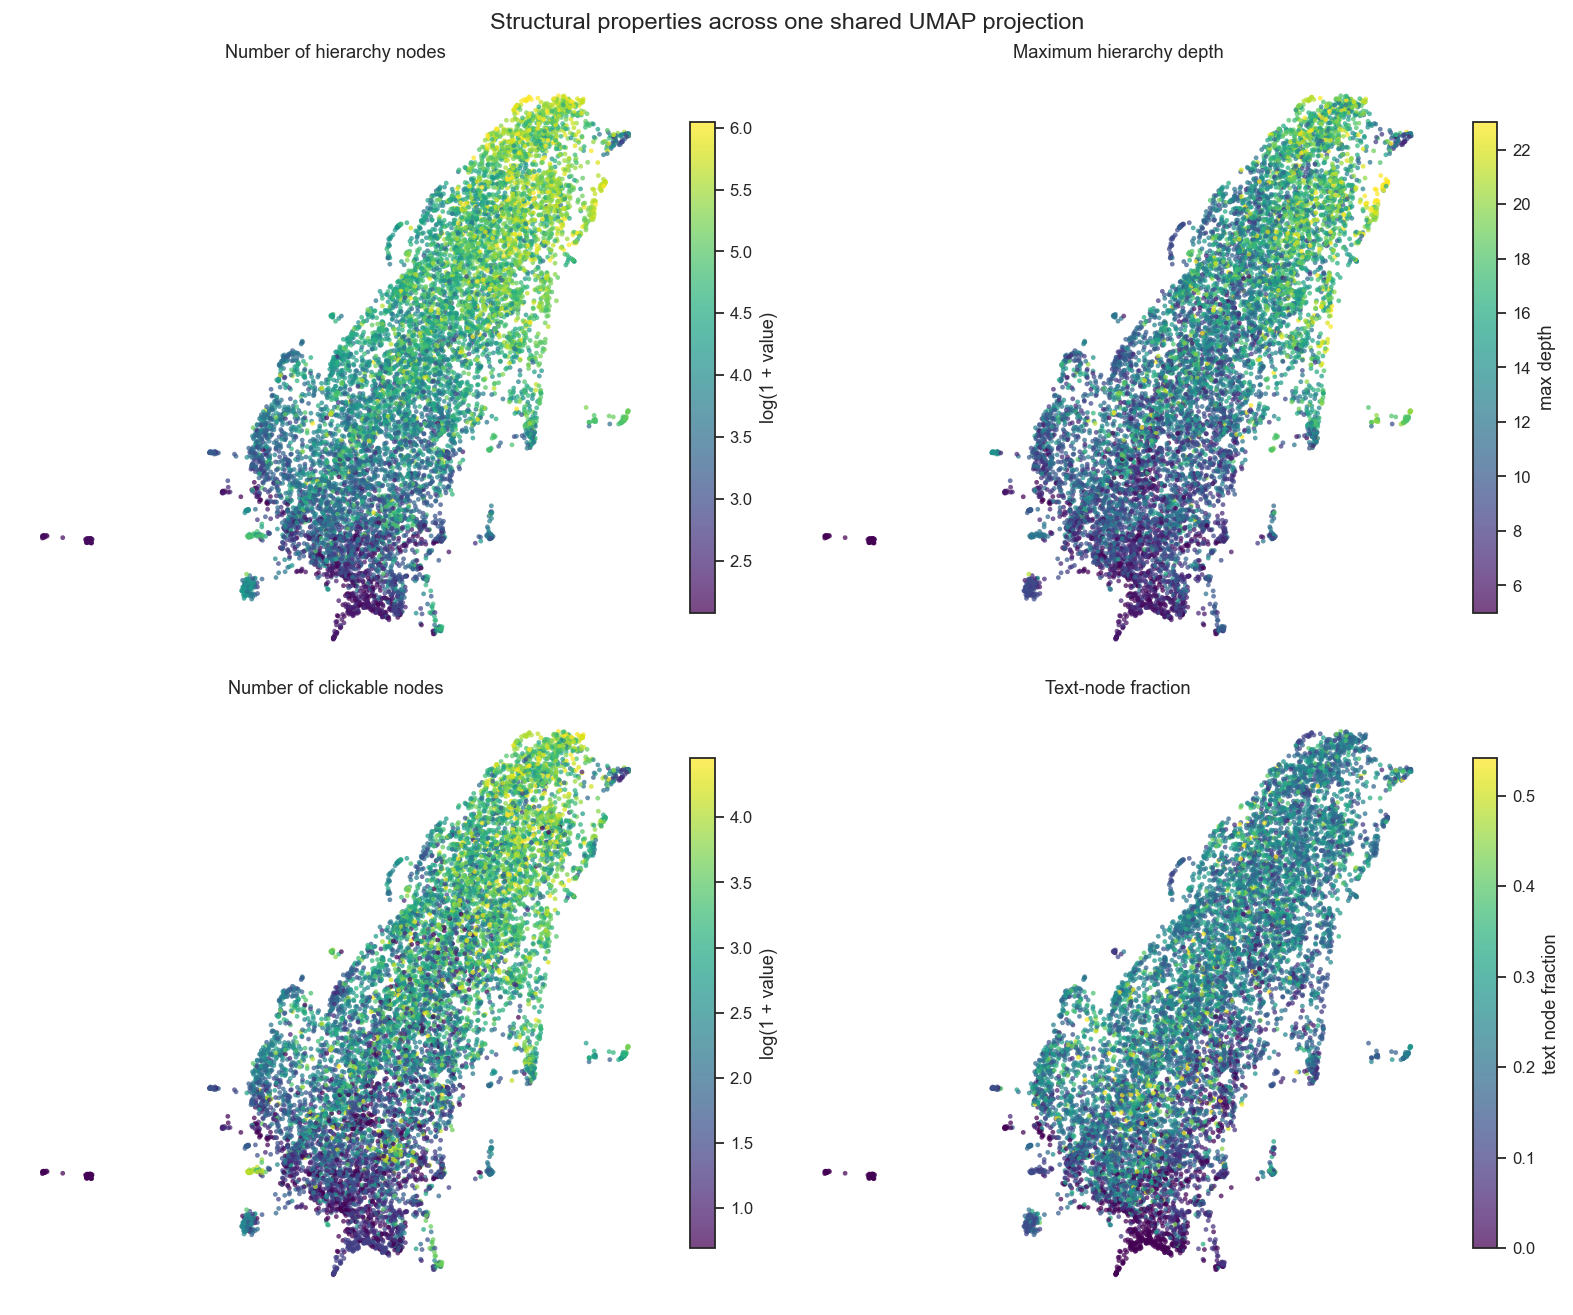

In [4]:
panels = [
    ("node_count", "Number of hierarchy nodes", True),
    ("max_depth", "Maximum hierarchy depth", False),
    ("clickable_count", "Number of clickable nodes", True),
    ("text_node_fraction", "Text-node fraction", False),
]
fig, axes = plt.subplots(2, 2, figsize=(12, 10), sharex=True, sharey=True, constrained_layout=True)
for ax, (column, title, use_log) in zip(axes.ravel(), panels):
    values = np.log1p(screens[column]) if use_log else screens[column]
    lo, hi = np.quantile(values, [0.01, 0.99])
    points = ax.scatter(screens["umap_1"], screens["umap_2"], c=values, cmap="viridis", vmin=lo, vmax=hi, s=7, alpha=0.72, linewidths=0, rasterized=True)
    colorbar = fig.colorbar(points, ax=ax, shrink=0.82)
    colorbar.set_label("log(1 + value)" if use_log else column.replace("_", " "))
    ax.set(title=title, xticks=[], yticks=[], xlabel="", ylabel="")
    sns.despine(ax=ax, left=True, bottom=True)
fig.suptitle("Structural properties across one shared UMAP projection", fontsize=13)
fig.savefig(OUTPUT_DIR / "hierarchy_complexity_umap.png", bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "hierarchy_complexity_umap.pdf", bbox_inches="tight")
plt.show()

## Original-space check

For each structural variable, compare its absolute difference between embedding neighbors and randomly paired screens. A neighbor/random ratio below one indicates that nearby embeddings are more structurally similar than chance pairs.

In [5]:
neighbor_model = NearestNeighbors(n_neighbors=K_NEIGHBORS + 1, metric="cosine").fit(X)
neighbor_indices = neighbor_model.kneighbors(X, return_distance=False)[:, 1:]
rng = np.random.default_rng(RANDOM_STATE)
random_indices = rng.integers(0, len(X), size=neighbor_indices.shape)
same_screen = random_indices == np.arange(len(X))[:, None]
while same_screen.any():
    random_indices[same_screen] = rng.integers(0, len(X), size=same_screen.sum())
    same_screen = random_indices == np.arange(len(X))[:, None]
same = random_indices == np.arange(len(X))[:, None]
while same.any():
    random_indices[same] = rng.integers(0, len(X), size=same.sum())
    same = random_indices == np.arange(len(X))[:, None]
rows = []
for column, title, use_log in panels:
    values = np.log1p(screens[column].to_numpy()) if use_log else screens[column].to_numpy()
    neighbor_difference = np.abs(values[:, None] - values[neighbor_indices]).mean()
    random_difference = np.abs(values[:, None] - values[random_indices]).mean()
    rows.append({"property": title, "neighbor difference": neighbor_difference, "random difference": random_difference, "neighbor/random": neighbor_difference / random_difference})
comparison = pd.DataFrame(rows)
display(comparison.style.format({"neighbor difference": "{:.3f}", "random difference": "{:.3f}", "neighbor/random": "{:.3f}"}))
screens.to_csv(OUTPUT_DIR / "hierarchy_complexity_umap.csv", index=False)
comparison.to_csv(OUTPUT_DIR / "hierarchy_complexity_neighbor_comparison.csv", index=False)

,property,neighbor difference,random difference,neighbor/random
0,Number of hierarchy nodes,0.559,1.118,0.500
1,Maximum hierarchy depth,2.885,4.961,0.581
2,Number of clickable nodes,0.674,1.158,0.582
3,Text-node fraction,0.085,0.126,0.675
